In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [2]:
chars = sorted(list(set(''.join(words))))
stoi = {s : i + 1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)


{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [3]:
block_size = 3
X, Y = [], []
for w in words:

    context = [0] * block_size
    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        context = context[1:] + [ix]

X = torch.tensor(X)
Y = torch.tensor(Y)

In [4]:
def build_dataset(words):
    block_size = 3
    X, Y = [], []
    for w in words:

        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))
Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [5]:
C = torch.randn((27, 2))

In [6]:
emb = C[X]

In [7]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)


In [8]:
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
h


tensor([[ 0.9214, -0.9741, -0.5826,  ...,  0.9925, -0.9653, -0.9825],
        [ 0.9756, -0.9862, -0.3942,  ...,  0.9985, -0.9999,  0.7610],
        [ 0.6172,  0.9990,  0.9837,  ...,  1.0000, -0.6223,  0.1962],
        ...,
        [-0.6360,  1.0000,  0.5442,  ...,  0.7126,  0.9705,  0.9872],
        [-0.8461,  0.8868, -0.8111,  ..., -0.8720,  0.3465,  0.9989],
        [ 0.7821,  0.9999,  0.9977,  ...,  0.9956, -0.7896,  0.1402]])

In [9]:
W2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [10]:
logits = h @ W2 + b2

In [11]:
counts = logits.exp()
prob = counts / counts.sum(1, keepdims=True)


In [12]:
loss = -prob[torch.arange(len(Y)), Y].log().mean()

In [13]:
Xtr.shape, Ytr.shape # dataset

(torch.Size([182625, 3]), torch.Size([182625]))

In [ ]:

n_embed = 10
n_hidden = 200
vocab_size = 27

g = torch.Generator().manual_seed(2147483647)

C = torch.randn((vocab_size, n_embed), generator=g)
W1 = torch.randn((n_embed * block_size, n_hidden), generator=g) * (5/3)/((n_embed * block_size)**0.5)
b1 = torch.randn(n_hidden, generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01
b2 = torch.randn(vocab_size, generator=g) * 0

bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))
bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True

12297


In [15]:
class Linear:

    def __init__(self, fan_in, fan_out, bias=True):
        self.weight = torch.randn((fan_in, fan_out), generator=g) / fan_in**0.5
        self.bias = torch.zeros(fan_out) if bias else None

    def __call__(self, x):
        self.out = x @ self.weight
        if self.bias is not None:
            self.out += self.bias
        return self.out
    
    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])

class BatchNorm1d:

    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True
        # parameters
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)
        # buffers
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)

    def __call__(self, x):
        # calculate the forward pass
        if self.training:
            xmean = x.mean(0, keepdim=True)
            xvar = x.var(0, keepdim=True, unbiased=True)
        else:
            xmean = self.running_mean
            xvar = self.running_var
        xhat = (x - xmean) / torch.sqrt(xvar + self.eps)
        self.out = self.gamma * xhat + self.beta
        # update buffers
        if self.training:
            with torch.no_grad():
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
                self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
        return self.out

    def parameters(self):
        return [self.gamma, self.beta]

class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out
    
    def parameters(self):
        return []

n_embd = 10
n_hidden = 100
g = torch.Generator().manual_seed(2147483647)

C = torch.randn((vocab_size, n_embd), generator=g)
layers = [
    Linear(n_embd * block_size, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, vocab_size, bias=False), BatchNorm1d(vocab_size),
]

with torch.no_grad():
    # Reduce initial confidence through the final BatchNorm scale.
    layers[-1].gamma *= 0.1

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True
    


47024


In [16]:
max_steps = 200000
batch_size = 32
lossi = []

# Restore batch statistics when training again after evaluation.
for layer in layers:
    layer.training = True

for i in range(max_steps):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward pass
    emb = C[Xb]
    x = emb.view(emb.shape[0], -1)
    for layer in layers:
        x = layer(x)

    loss = F.cross_entropy(x, Yb)

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    lr = 0.1 if i < 150000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10000 == 0:
        print(f'{i:7d} / {max_steps:7d}: {loss.item():.4f}')
        
    lossi.append(loss.log10().item())
    

      0 /  200000: 3.2870
  10000 /  200000: 2.3273
  20000 /  200000: 2.1019
  30000 /  200000: 1.9020
  40000 /  200000: 2.1643
  50000 /  200000: 2.1520
  60000 /  200000: 1.7767
  70000 /  200000: 2.1514
  80000 /  200000: 2.3802
  90000 /  200000: 1.9338
 100000 /  200000: 2.3943
 110000 /  200000: 2.1508
 120000 /  200000: 2.1813
 130000 /  200000: 2.0889
 140000 /  200000: 1.8096
 150000 /  200000: 1.9132
 160000 /  200000: 1.9793
 170000 /  200000: 1.9654
 180000 /  200000: 2.2462
 190000 /  200000: 1.9601


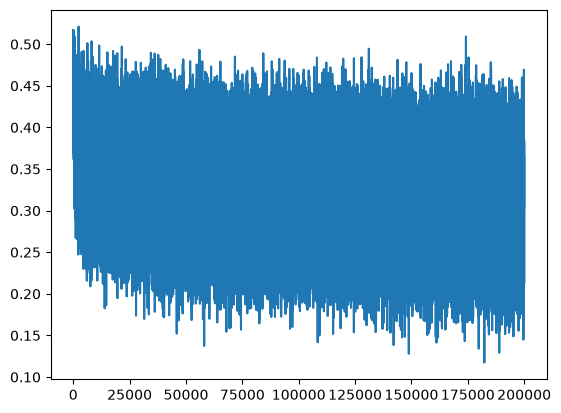

In [17]:
plt.plot(lossi)

In [18]:
@torch.no_grad()
def split_loss(split):
    x, y = {
        'train': (Xtr, Ytr),
        'val' : (Xdev, Ydev),
        'test': (Xte, Yte)
    }[split]

    emb = C[x]
    x = emb.view(emb.shape[0], -1)
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, y)
    print(split, loss.item())

# Use running statistics instead of current-batch statistics.
for layer in layers:
    layer.training = False

split_loss('train')
split_loss('val')

train 1.9998632669448853
val 2.077087640762329


In [19]:
g = torch.Generator().manual_seed(2147483647 + 10)
for layer in layers:
    layer.training = False

with torch.no_grad():
    for _ in range(20):
        out = []
        context = [0] * block_size
        while True:
            # Forward pass through the same layers used for training.
            emb = C[torch.tensor([context])]
            x = emb.view(1, -1)
            for layer in layers:
                x = layer(x)
            probs = F.softmax(x, dim=1)
            ix = torch.multinomial(probs, num_samples=1, generator=g).item()
            context = context[1:] + [ix]
            out.append(ix)
            if ix == 0:
                break

        print(''.join(itos[i] for i in out))


carlah.
amelle.
khyim.
shreety.
skanden.
jazhiel.
deliah.
jareei.
nellara.
chaiivon.
leigh.
ham.
joce.
quintis.
lilea.
jadilyn.
jermaijaryxia.
kaellissa.
med.
edi.
